In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

In [23]:
data= pd.read_excel("C:/Users/HP/Downloads/Malaria_Data.xlsx")
print(data)

print(data.head())
print(data.columns)

         Continent    Country  Year  Malaria cases  Malaria deaths  \
0    South America  Argentina  2000            440               0   
1    South America  Argentina  2001            215               0   
2    South America  Argentina  2002            125               0   
3    South America  Argentina  2003            124               1   
4    South America  Argentina  2004            116               0   
..             ...        ...   ...            ...             ...   
248  South America  Venezuela  2018         474766             373   
249  South America  Venezuela  2019         466830             350   
250  South America  Venezuela  2020         223067             196   
251  South America  Venezuela  2021         204424             155   
252  South America  Venezuela  2022         154089             125   

     Malaria incidence  Malaria mortality  Indigenous cases  P. falciparum  \
0                 2.36               0.00                 0              0   
1  

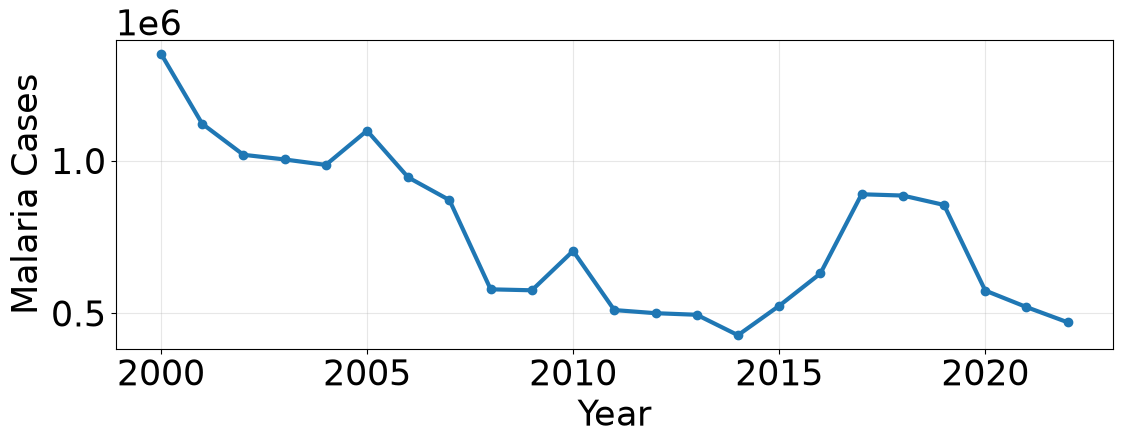

In [25]:
##overall trend


overall_series = (
    data.groupby('Year')['Malaria cases']
    .sum()
    .sort_index()
    .reindex(range(2000, 2023))
)

plt.figure(figsize=(12, 5))

plt.plot(
    overall_series.index,
    overall_series.values,
    marker='o',
    linewidth=3
)


plt.xlabel("Year")
plt.ylabel("Malaria Cases")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

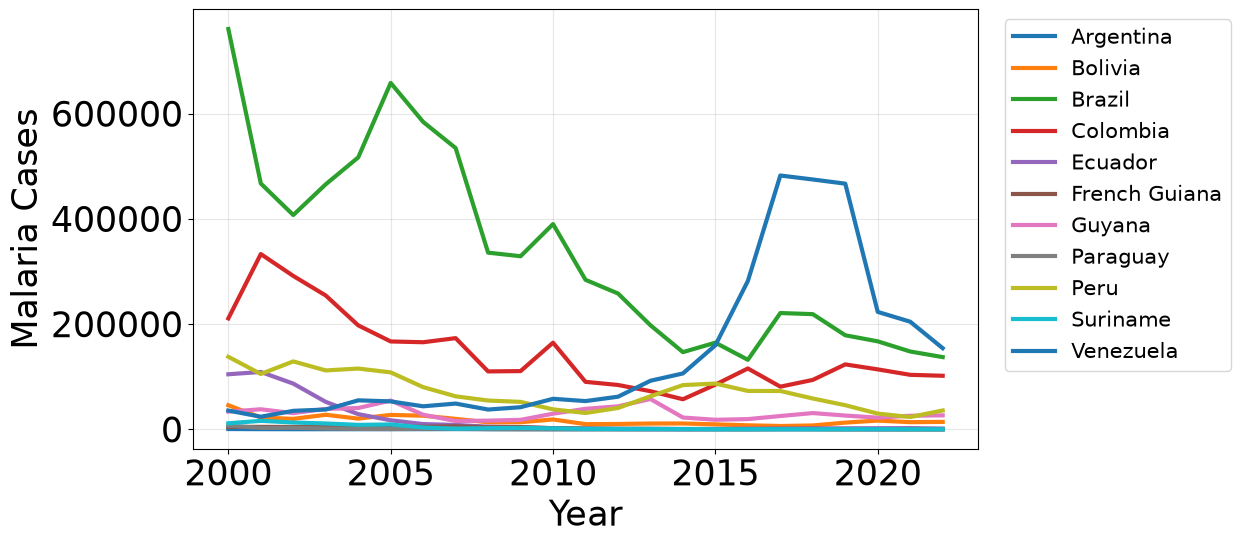

In [26]:
#country-wise trend

import matplotlib.pyplot as plt 
import pandas as pd
plt.rcParams.update({
    'font.size': 25,
    'axes.titlesize': 25,
    'axes.labelsize': 25,
    'xtick.labelsize': 25,
    'ytick.labelsize': 25,
    'legend.fontsize': 15,
})
countries = sorted(data['Country'].unique())
plt.figure(figsize=(13, 6))

for country in countries:
    temp = data[data['Country'] == country]
    plt.plot(
        temp['Year'],
        temp['Malaria cases'],
        label=country,
        linewidth=3
    )


plt.xlabel("Year")
plt.ylabel("Malaria Cases")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# ager
result = adfuller(y.dropna())

print("ADF Statistic:", result[0])
print("P-value:", result[1])

if result[1] < 0.05:
    print("Data is stationary")
else:
    print("Data is non-stationary")

ADF Statistic: -1.6961811928615298
P-value: 0.43308110753323487
Data is non-stationary


In [44]:
#Overall Analysis

import itertools
from statsmodels.tsa.arima.model import ARIMA

results = []

for p, q in itertools.product(range(3), repeat=2):
    try:
        model = ARIMA(y, order=(p, 2, q)).fit()
        results.append([p, 2, q, model.aic, model.bic])
    except:
        pass

result = pd.DataFrame(results,
    columns=['p','d','q','AIC','BIC'])

print(result.sort_values('AIC'))

   p  d  q         AIC         BIC
4  1  2  1  566.624763  569.758330
1  0  2  1  567.278212  569.367257
2  0  2  2  567.343336  570.476904
8  2  2  2  567.666308  572.888921
3  1  2  0  568.141804  570.230849
5  1  2  2  568.296969  572.475059
7  2  2  1  568.527990  572.706080
0  0  2  0  568.729585  569.774108
6  2  2  0  568.889545  572.023112


In [45]:
## ARIMA mosel selection

from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd

y = data.groupby('Year')['Malaria cases'].sum()

train = y.loc[2000:2017]
test = y.loc[2018:2022]

print(train)
orders = [(0,2,0), (1,2,0), (0,2,1), (0,2,2),(2,2,2),(1,2,0),(1,2,2),
          (1,2,1), (2,2,0), (2,2,1)]

   
results = []

for order in orders:
    model = ARIMA(np.log1p(train), order=order).fit()

    results.append([order, model.aic, model.bic])

table = pd.DataFrame(
    results, columns=['ARIMA', 'AIC', 'BIC']
)

print(table.sort_values('AIC'))

Year
2000    1351663
2001    1121724
2002    1019887
2003    1004549
2004     986692
2005    1098967
2006     945604
2007     871280
2008     578622
2009     575444
2010     704455
2011     510614
2012     500353
2013     495159
2014     428165
2015     524509
2016     630589
2017     890410
Name: Malaria cases, dtype: int64
       ARIMA       AIC       BIC
2  (0, 2, 1) -1.564135 -0.018958
8  (2, 2, 0)  0.099911  2.417677
3  (0, 2, 2)  0.407758  2.725524
7  (1, 2, 1)  0.413685  2.731451
5  (1, 2, 0)  0.435336  1.980514
1  (1, 2, 0)  0.435336  1.980514
9  (2, 2, 1)  0.702741  3.793095
6  (1, 2, 2)  1.653121  4.743476
0  (0, 2, 0)  2.168717  2.941306
4  (2, 2, 2)  2.633653  6.496597


In [47]:
## Best ARIMA model selection

best_order = tuple(
    min(results, key=lambda x: x[1])[0]
)

print("Best ARIMA Model:", best_order)

best_model = ARIMA(
    np.log1p(train), order=best_order
).fit()

print(best_model.summary())

Best ARIMA Model: (0, 2, 1)
                               SARIMAX Results                                
Dep. Variable:          Malaria cases   No. Observations:                   18
Model:                 ARIMA(0, 2, 1)   Log Likelihood                   2.782
Date:                Wed, 18 Nov 2026   AIC                             -1.564
Time:                        00:12:32   BIC                             -0.019
Sample:                             0   HQIC                            -1.485
                                 - 18                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.6858      0.249     -2.756      0.006      -1.173      -0.198
sigma2         0.0397      0.020      2.005      0.045       0.001       0.079
Ljung-Box (L1) (Q):     

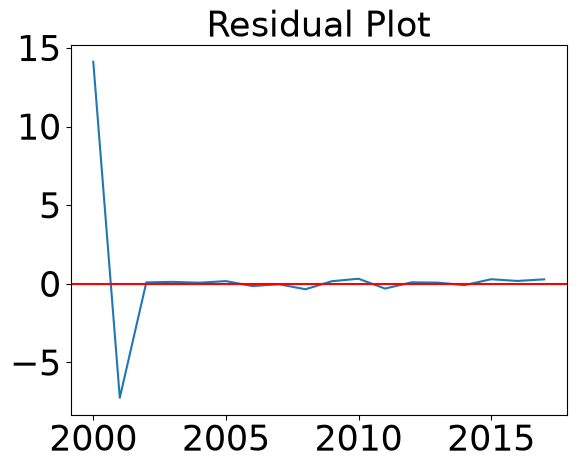

    lb_stat  lb_pvalue
5  3.439355   0.632583


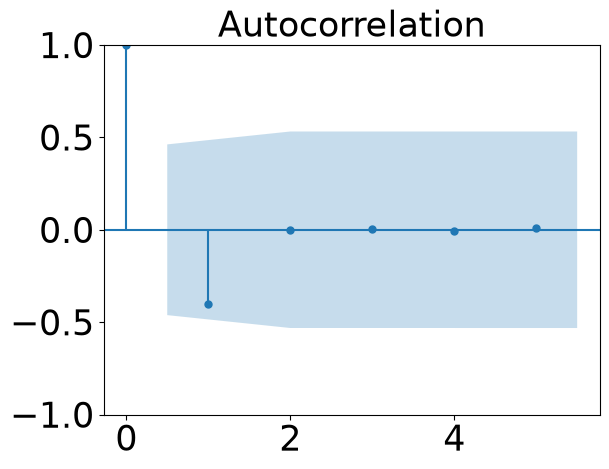

In [48]:
##Diagnostic Test

from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt

residual = best_model.resid

# Residual plot
plt.plot(residual)
plt.axhline(0, color='red')
plt.title("Residual Plot")
plt.show()

# Ljung-Box test
print(acorr_ljungbox(residual, lags=[5],
                     return_df=True))

# Residual ACF
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(residual, lags=5)
plt.show()

In [49]:
# Training data
train = y.iloc[:-3]

# Testing data
test = y.iloc[-3:]

print("Training data:")
print(train)

print("Testing data:")
print(test)

Training data:
Year
2000    1351663
2001    1121724
2002    1019887
2003    1004549
2004     986692
2005    1098967
2006     945604
2007     871280
2008     578622
2009     575444
2010     704455
2011     510614
2012     500353
2013     495159
2014     428165
2015     524509
2016     630589
2017     890410
2018     886191
2019     855365
Name: Malaria cases, dtype: int64
Testing data:
Year
2020    574576
2021    520410
2022    470498
Name: Malaria cases, dtype: int64


In [50]:
from statsmodels.tsa.arima.model import ARIMA
# Year-wise total malaria cases
ts = data.groupby('Year')['Malaria cases'].sum().sort_index()

best_order = (0, 2, 1)  

final_model = ARIMA(ts, order=best_order).fit()

forecast = final_model.forecast(steps=6)
forecast.index = range(2023, 2029)

print("Malaria Cases Forecast:")
print(forecast.round(0))

Malaria Cases Forecast:
2023    409691.0
2024    348884.0
2025    288077.0
2026    227270.0
2027    166463.0
2028    105656.0
Name: predicted_mean, dtype: float64


In [52]:
## COUNTRY - WISE FORECASTING


import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_squared_error, mean_absolute_error




# 2. Country-wise analysis
for country, df in data.groupby("Country"):

    y = (df.set_index("Year")["Malaria cases"]
         .sort_index().reindex(range(2000, 2023)))

    if y.isna().any():
        print("Missing data:", country)
        continue

    train = y.loc[2000:2017].values
    test = y.loc[2018:2022].values


# 3. ARIMA model selection
    results = []

    for p in range(3):
        for d in range(3):
            for q in range(3):
                try:
                    trend = "c" if d == 0 else "n"

                    m = ARIMA(train, order=(p,d,q),
                              trend=trend).fit()

                    if not m.mle_retvals.get("converged", True):
                        continue

                    k = len(m.params)
                    n = len(train)
                    aicc = m.aic + 2*k*(k+1)/(n-k-1)

                    lb = acorr_ljungbox(
                        m.resid, lags=[5],
                        model_df=p+q, return_df=True
                    )["lb_pvalue"].iloc[0]

                    results.append((aicc, (p,d,q),
                                    trend, lb))

                except:
                    pass

    if not results:
        print("No model found:", country)
        continue

    
# Prefer white-noise residuals, then lowest AICc
    
    good = [r for r in results
            if pd.notna(r[3]) and r[3] > 0.05]

    best = min(good if good else results,
               key=lambda x: x[0])

    aicc, order, trend, lb_p = best

    
    
# 4. Test performance
   
    m = ARIMA(train, order=order, trend=trend).fit()
    pred = np.maximum(m.forecast(5), 0)

    rmse = np.sqrt(mean_squared_error(test, pred))
    mae = mean_absolute_error(test, pred)

    # 5. Final model and forecast
    final = ARIMA(y.values, order=order,
                  trend=trend).fit()

    fc = final.get_forecast(steps=10)
    values = np.maximum(fc.predicted_mean, 0)
    ci = fc.conf_int()

    models.append({
        "Country": country,
        "Best_ARIMA": order,
        "AICc": aicc,
        "RMSE": rmse,
        "MAE": mae,
        "Ljung_Box_p": lb_p,
        "Diagnostic": "Pass" if pd.notna(lb_p) and lb_p > 0.05 else "Fail"
    })

    forecasts.append(pd.DataFrame({
        "Country": country,
        "Year": range(2023, 2033),
        "Forecast": values,
        "Lower_95": np.maximum(ci[:,0], 0),
        "Upper_95": np.maximum(ci[:,1], 0)
    }))


# 6. Results

model_table = pd.DataFrame(models)
forecast_table = pd.concat(forecasts, ignore_index=True)

print("\nBEST COUNTRY-WISE ARIMA MODELS")
print(model_table.round(2).to_string(index=False))

print("\nCOUNTRY-WISE FORECAST 2023-2032")
print(forecast_table.round(2).to_string(index=False))


# 7. Save results
model_table.to_excel("Best_ARIMA_Models.xlsx", index=False)
forecast_table.to_excel("Malaria_Forecast_2023_2032.xlsx",
                        index=False)

print("\nForecasting Completed!")




BEST COUNTRY-WISE ARIMA MODELS
      Country Best_ARIMA   AICc      RMSE       MAE  Ljung_Box_p Diagnostic
    Argentina  (1, 2, 0) 197.18      0.00      0.00         0.23       Pass
      Bolivia  (2, 2, 0) 325.37  11819.70  10914.65         0.14       Pass
       Brazil  (0, 2, 1) 417.40 168099.87 150565.23         0.33       Pass
     Colombia  (0, 2, 2) 399.01  62669.05  61826.89         0.53       Pass
      Ecuador  (2, 2, 1) 319.13   1786.40   1762.95         0.06       Pass
French Guiana  (0, 2, 1) 268.91    145.59    136.22         0.74       Pass
       Guyana  (0, 2, 1) 358.72   4916.51   4610.81         0.73       Pass
     Paraguay  (0, 2, 1) 256.44      0.00      0.00         0.15       Pass
         Peru  (1, 2, 0) 355.83  23876.76  22097.60         0.35       Pass
     Suriname  (0, 2, 0) 303.84    278.71    253.60         0.48       Pass
    Venezuela  (0, 2, 0) 379.21 882594.47 779205.80         0.96       Pass
    Argentina  (1, 2, 0) 197.18      0.00      0.00     